# Preprocessing medical images: from mixed scans to one common grid
### Class example · OrganDataBefore → OrganDataProcessed

Scans from different patients, scanners and protocols almost never share the same voxel size or image size.
A neural network sees **voxels, not millimetres**, so before training we bring every scan onto **one common grid**:

```
OrganDataBefore/  (17 MR scans + organ masks, every scan with its own spacing and size)
  → 1. find image/mask pairs
  → 2. list the data: size, spacing, physical extent, dtype      (read the header only: fast)
  → 3. load the voxels, check the mask fits the image, look at the data
  → 4. RESAMPLE to the same spacing: 1 × 1 × 2 mm
  → 5. CROP or PAD to the same size: 192 × 192 × 48 voxels
  → 6. check the result (same grid? organ volumes unchanged?)
  → 7. save to OrganDataProcessed/ (image float32, mask uint8)
```

**Words used below**
* **size**: number of voxels along x, y, z, e.g. `(229, 229, 50)`.
* **spacing**: size of one voxel in mm along x, y, z, e.g. `(0.79, 0.79, 1.45)`. z is the distance between slices.
* **physical extent** = size × spacing: how many mm the scan covers. Resampling changes size and spacing, but **not** the extent.
* **dtype**: how each voxel value is stored (`float32`, `int8`, ...), which decides precision and file size.

In [14]:
# Run once if needed (then restart the kernel)
# %pip install SimpleITK numpy pandas matplotlib

## 0 · Setup and settings

In [15]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import SimpleITK as sitk

DATA_DIR  = Path("../../OrganDataBefore")       # input: relative to this notebook (scripts/)
OUT_DIR   = Path("../../OrganDataProcessed")    # output folder
IMG_SUFFIX, MASK_SUFFIX = "_img", "_mask"    # 001000_img.nii + 001000_mask.nii

TARGET_SPACING = (1.0, 1.0, 2.0)             # mm, in SimpleITK order (x, y, z)
TARGET_SIZE    = (192, 192, 48)              # voxels (x, y, z); divisible by 16, handy for a U-Net

pd.set_option("display.width", 200)

## 1 · Find image/mask pairs

Each case is two files with the same ID: the scan (`_img`) and its organ mask (`_mask`, labels 0 = background, 1–8 = organs).
We pair them by name and skip any image without a mask.

In [16]:
def find_pairs(folder):
    pairs = []
    for img_path in sorted(Path(folder).glob(f"*{IMG_SUFFIX}.nii*")):
        mask_path = img_path.with_name(img_path.name.replace(IMG_SUFFIX, MASK_SUFFIX))
        if mask_path.exists():
            pairs.append((img_path, mask_path))
        else:
            print("No mask for", img_path.name, "-> skipped")
    return pairs

pairs = find_pairs(DATA_DIR)
print(f"{len(pairs)} image/mask pairs in {DATA_DIR.resolve()}")
assert pairs, "No pairs found: check DATA_DIR"

17 image/mask pairs in <teaching-data>/OrganDataBefore


## 2 · List the data information (header only)

A NIfTI file starts with a small **header** (size, spacing, origin, direction, dtype) followed by the voxels.
`sitk.ImageFileReader().ReadImageInformation()` reads **only the header**, so we can inspect a whole dataset in a second, even when the files are hundreds of MB.

In [17]:
def header_info(path):
    reader = sitk.ImageFileReader()
    reader.SetFileName(str(path))
    reader.ReadImageInformation()                     # header only, no voxels loaded
    return reader

rows = []
for img_path, mask_path in pairs:
    hi, hm = header_info(img_path), header_info(mask_path)
    size, spacing = np.array(hi.GetSize()), np.array(hi.GetSpacing())
    rows.append({
        "case": img_path.name.replace(IMG_SUFFIX, "").split(".")[0],
        "size (x,y,z)": tuple(int(s) for s in size),
        "spacing mm (x,y,z)": tuple(round(float(s), 2) for s in spacing),
        "extent mm (x,y,z)": tuple(int(round(e)) for e in size * spacing),
        "orientation": sitk.DICOMOrientImageFilter.GetOrientationFromDirectionCosines(hi.GetDirection()),
        "image dtype": sitk.GetPixelIDValueAsString(hi.GetPixelID()),
        "mask dtype": sitk.GetPixelIDValueAsString(hm.GetPixelID()),
        "image MB": round(img_path.stat().st_size / 1e6, 1),
        "mask MB": round(mask_path.stat().st_size / 1e6, 1),
    })
info = pd.DataFrame(rows)
info

,case,"size (x,y,z)","spacing mm (x,y,z)","extent mm (x,y,z)",orientation,image dtype,mask dtype,image MB,mask MB
0,001000,"(229, 229, 50)","(0.79, 0.79, 1.45)","(180, 180, 72)",LPS,32-bit float,8-bit signed integer,10.5,2.6
1,001001,"(607, 607, 241)","(0.33, 0.33, 0.37)","(200, 200, 90)",LPS,32-bit float,8-bit signed integer,355.2,88.8
2,001002,"(102, 102, 37)","(1.76, 1.76, 1.94)","(180, 180, 72)",LPS,32-bit float,8-bit signed integer,1.5,0.4
3,001003,"(129, 129, 50)","(1.39, 1.39, 1.61)","(180, 180, 81)",LPS,32-bit float,8-bit signed integer,3.3,0.8
4,001004,"(141, 141, 36)","(1.28, 1.28, 1.98)","(180, 180, 71)",LPS,32-bit float,8-bit signed integer,2.9,0.7
5,001005,"(590, 590, 41)","(0.3, 0.3, 1.77)","(180, 180, 73)",LPS,32-bit float,8-bit signed integer,57.1,14.3
6,001006,"(499, 499, 51)","(0.36, 0.36, 1.84)","(180, 180, 94)",LPS,32-bit float,8-bit signed integer,50.8,12.7
7,002000,"(308, 308, 45)","(0.62, 0.62, 1.61)","(190, 190, 73)",LPS,32-bit float,8-bit signed integer,17.1,4.3
8,002002,"(141, 141, 46)","(1.27, 1.27, 1.85)","(180, 180, 85)",LPS,32-bit float,8-bit signed integer,3.7,0.9
9,002003,"(237, 237, 68)","(0.84, 0.84, 1.06)","(199, 199, 72)",LPS,32-bit float,8-bit signed integer,15.3,3.8


**What to notice**
* **Spacing** differs for every case: in-plane from ~0.3 to ~2.1 mm, and z (slice spacing) is always the largest.
* So **size** differs a lot too (from ~100² to ~600² voxels), although the **extent** in mm is similar (~180–200 mm in-plane). It is the same kind of anatomy, sampled on very different grids.
* A network would see an organ that is 50 voxels wide in one scan and 250 voxels wide in another. Resampling to one spacing fixes this.
* **dtype**: images are `float32`, masks `int8` (labels 0–8 fit easily; see `OrganDataBeforeLarge` for how much bigger the same data gets as `float64`).

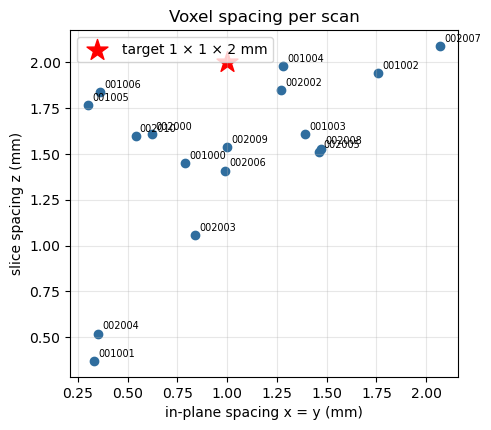

In [18]:
# Spacing at a glance: every dot is one scan. Our target spacing is the red star.
sp = np.array(info["spacing mm (x,y,z)"].tolist())
plt.figure(figsize=(5, 4.5))
plt.scatter(sp[:, 0], sp[:, 2], color="#2f6d9e")
for (x, z), name in zip(sp[:, [0, 2]], info["case"]):
    plt.annotate(name, (x, z), fontsize=7, xytext=(3, 3), textcoords="offset points")
plt.scatter(TARGET_SPACING[0], TARGET_SPACING[2], marker="*", s=250, color="red", label="target 1 × 1 × 2 mm")
plt.xlabel("in-plane spacing x = y (mm)"); plt.ylabel("slice spacing z (mm)")
plt.title("Voxel spacing per scan"); plt.legend(); plt.grid(alpha=0.3); plt.show()

## 3 · Load the voxels and check them

Now we read the voxels. For every case we check:
1. **Image and mask have the same geometry** (size, spacing, origin). A mask that does not fit its image is a silent error that ruins training.
2. **Orientation**: reorient to **LPS** so that array axis *k* means the same direction in every scan (already LPS here, but cheap to enforce).
3. **Intensity range** and **label values**, so that we know what we are working with.

We read the image as `float32` and the mask as `uint8` directly, whatever type is stored in the file.

In [19]:
def load_case(img_path, mask_path):
    img = sitk.DICOMOrient(sitk.ReadImage(str(img_path), sitk.sitkFloat32), "LPS")
    mask = sitk.DICOMOrient(sitk.ReadImage(str(mask_path), sitk.sitkUInt8), "LPS")
    same = (img.GetSize() == mask.GetSize()
            and np.allclose(img.GetSpacing(), mask.GetSpacing(), atol=1e-4)
            and np.allclose(img.GetOrigin(), mask.GetOrigin(), atol=1e-3))
    assert same, f"{img_path.name}: mask geometry does not match the image!"
    return {"case": img_path.name.replace(IMG_SUFFIX, "").split(".")[0], "img": img, "mask": mask}

cases = [load_case(i, m) for i, m in pairs]

def organ_volumes_ml(mask):
    # volume of every label in ml = voxel count × voxel volume (mm³) / 1000
    arr = sitk.GetArrayViewFromImage(mask)
    voxel_ml = np.prod(mask.GetSpacing()) / 1000
    return {k: np.count_nonzero(arr == k) * voxel_ml for k in range(1, int(arr.max()) + 1)}

pd.DataFrame([{
    "case": c["case"],
    "intensity min": round(float(sitk.GetArrayViewFromImage(c["img"]).min()), 2),
    "intensity max": round(float(sitk.GetArrayViewFromImage(c["img"]).max()), 2),
    "label values": np.unique(sitk.GetArrayViewFromImage(c["mask"])).tolist(),
    "all organs (ml)": round(sum(organ_volumes_ml(c["mask"]).values()), 1),
} for c in cases])

,case,intensity min,intensity max,label values,all organs (ml)
0,001000,0.0,1.00,"[0, 1, 2, 3, 4, 5, 6, 7, 8]",313.6
1,001001,0.0,2208.69,"[0, 1, 2, 3, 4, 5, 6, 7, 8]",377.0
2,001002,0.0,0.96,"[0, 1, 2, 3, 4, 5, 6, 7, 8]",238.2
3,001003,0.0,0.97,"[0, 1, 2, 3, 4, 5, 6, 7, 8]",366.6
4,001004,0.0,0.97,"[0, 1, 2, 3, 4, 5, 6, 7, 8]",282.4
5,001005,0.0,0.99,"[0, 1, 2, 3, 4, 5, 6, 7, 8]",247.4
6,001006,0.0,546.59,"[0, 1, 2, 3, 4, 5, 6, 7, 8]",312.1
7,002000,0.0,1.00,"[0, 1, 2, 3, 4, 5, 6, 7, 8]",299.8
8,002002,0.0,0.94,"[0, 1, 2, 3, 4, 5, 6, 7, 8]",316.4
9,002003,0.0,0.84,"[0, 1, 2, 3, 4, 5, 6, 7, 8]",281.1


Intensities differ between scans (some 0–1, some up to ~2000). That is normal for MR, which has no fixed units.
We do **not** change intensities here: that is **normalisation**, usually done per volume when the data are loaded for training (see the U-Net notebook).

### Look at the raw data
Below, the middle axial slice of three scans is drawn **in voxels** (top: the axes are voxel indices) and **in millimetres** (bottom).
In voxels the same anatomy looks very different in size. In mm, it looks the same. This is the problem resampling solves.

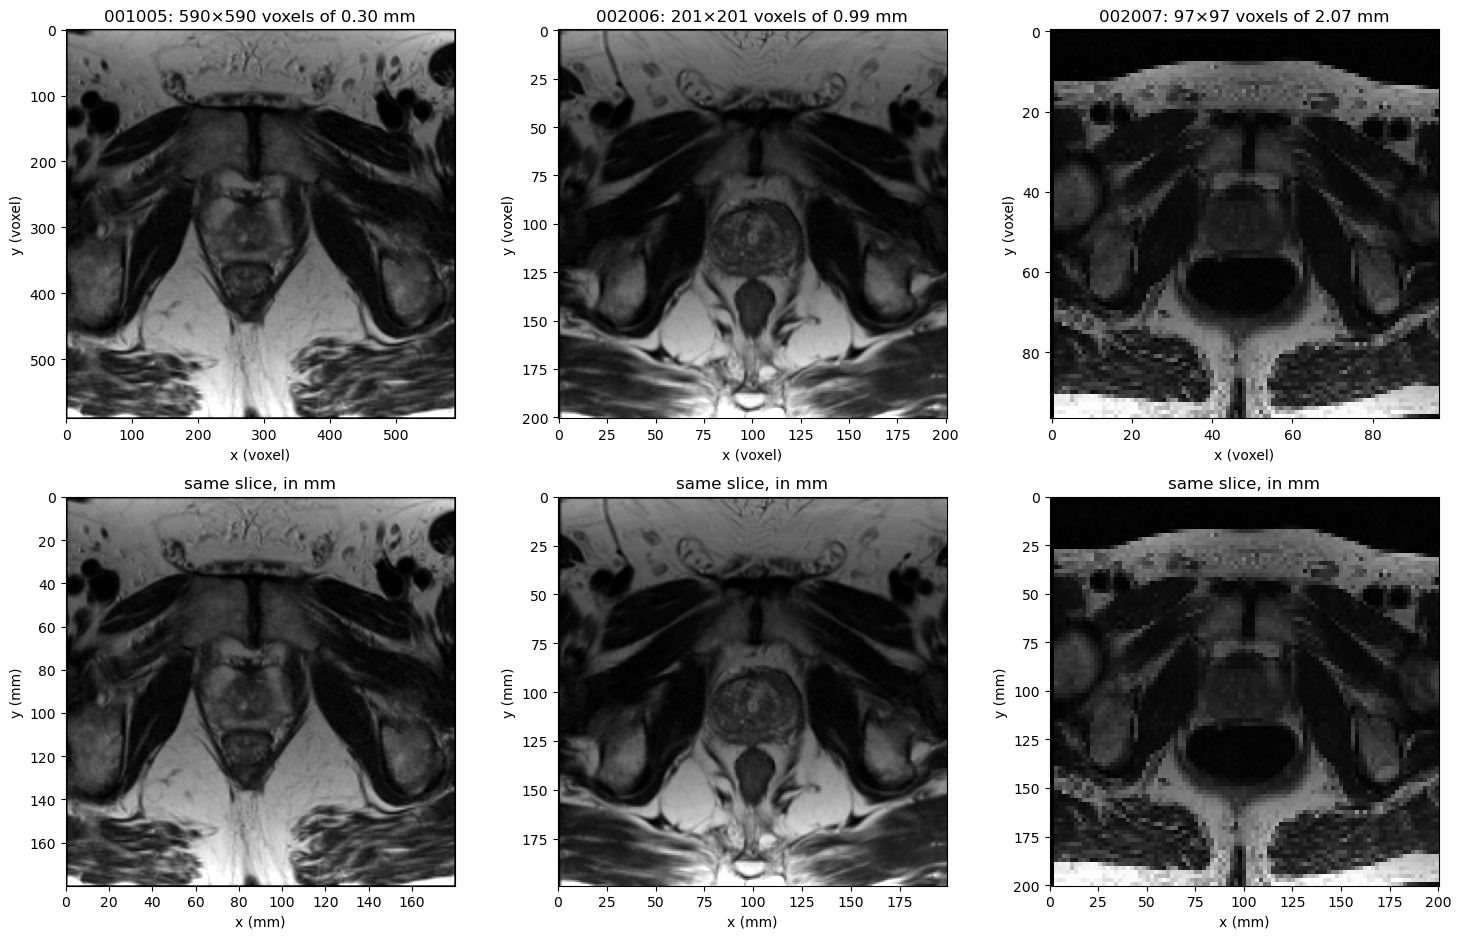

In [21]:
def mid_slice(img):
    arr = sitk.GetArrayViewFromImage(img)           # numpy order (z, y, x)
    return arr[arr.shape[0] // 2]

def grey_range(a):
    return np.percentile(a, [1, 99.5])

show = sorted(cases, key=lambda c: c["img"].GetSpacing()[0])
show = [show[0], show[len(show) // 2], show[-1]]       # finest, middle and coarsest in-plane spacing
fig, axes = plt.subplots(2, 3, figsize=(15, 9.5))
for col, c in enumerate(show):
    sl, (sx, sy, _) = mid_slice(c["img"]), c["img"].GetSpacing()
    lo, hi = grey_range(sl)
    axes[0, col].imshow(sl, cmap="gray", vmin=lo, vmax=hi)
    axes[0, col].set_title(f'{c["case"]}: {sl.shape[1]}×{sl.shape[0]} voxels of {sx:.2f} mm')
    axes[0, col].set_xlabel("x (voxel)"); axes[0, col].set_ylabel("y (voxel)")
    ny, nx = sl.shape
    axes[1, col].imshow(sl, cmap="gray", vmin=lo, vmax=hi, extent=(0, nx * sx, ny * sy, 0))
    axes[1, col].set_xlabel("x (mm)"); axes[1, col].set_ylabel("y (mm)")
    axes[1, col].set_title("same slice, in mm")
plt.tight_layout(); plt.show()

## 4 · Resample to the same spacing: 1 × 1 × 2 mm

**Resampling** computes the image on a new voxel grid that covers the same physical region.

* New size along each axis: `new_size = round(old_size × old_spacing / new_spacing)`.
  For example, 229 voxels × 0.79 mm = 180 mm → 180 voxels of 1 mm.
* Origin and direction stay the same, so the anatomy stays in the same place in the scanner coordinates.
* **Interpolation** decides how new voxel values are computed from old ones:
  * **Image → linear**: a smooth weighted average of the neighbours. Good for intensities. (B-spline is smoother but slower.)
  * **Mask → nearest neighbour**: copy the closest label. Linear would create values like 2.5 between organ 2 and organ 3, which is not a valid label!
* Voxels outside the original scan get the value 0.

Why 1 × 1 × 2 mm? It is close to the typical resolution of these scans. Going much finer only makes the files bigger without adding real detail; going much coarser loses small organs.

In [ ]:
def resample_to_spacing(image, new_spacing, is_mask):
    old_size, old_spacing = np.array(image.GetSize()), np.array(image.GetSpacing())
    new_size = [int(round(s)) for s in old_size * old_spacing / np.array(new_spacing)]
    return sitk.Resample(
        image, new_size, sitk.Transform(),                       # identity transform: same physical space
        sitk.sitkNearestNeighbor if is_mask else sitk.sitkLinear,
        image.GetOrigin(), new_spacing, image.GetDirection(),
        0, image.GetPixelID())                                   # 0 outside the scan, keep the dtype

rows = []
for c in cases:
    c["img_rs"] = resample_to_spacing(c["img"], TARGET_SPACING, is_mask=False)
    c["mask_rs"] = resample_to_spacing(c["mask"], TARGET_SPACING, is_mask=True)
    rows.append({"case": c["case"],
                 "spacing before": tuple(round(s, 2) for s in c["img"].GetSpacing()),
                 "size before": c["img"].GetSize(),
                 "spacing after": c["img_rs"].GetSpacing(),
                 "size after": c["img_rs"].GetSize()})
resampled = pd.DataFrame(rows)
resampled

,case,spacing before,size before,spacing after,size after
0,001000,"(0.79, 0.79, 1.45)","(229, 229, 50)","(1.0, 1.0, 2.0)","(180, 180, 36)"
1,001001,"(0.33, 0.33, 0.37)","(607, 607, 241)","(1.0, 1.0, 2.0)","(200, 200, 45)"
2,001002,"(1.76, 1.76, 1.94)","(102, 102, 37)","(1.0, 1.0, 2.0)","(180, 180, 36)"
3,001003,"(1.39, 1.39, 1.61)","(129, 129, 50)","(1.0, 1.0, 2.0)","(180, 180, 40)"
4,001004,"(1.28, 1.28, 1.98)","(141, 141, 36)","(1.0, 1.0, 2.0)","(180, 180, 36)"
5,001005,"(0.3, 0.3, 1.77)","(590, 590, 41)","(1.0, 1.0, 2.0)","(180, 180, 36)"
6,001006,"(0.36, 0.36, 1.84)","(499, 499, 51)","(1.0, 1.0, 2.0)","(180, 180, 47)"
7,002000,"(0.62, 0.62, 1.61)","(308, 308, 45)","(1.0, 1.0, 2.0)","(190, 190, 36)"
8,002002,"(1.27, 1.27, 1.85)","(141, 141, 46)","(1.0, 1.0, 2.0)","(180, 180, 43)"
9,002003,"(0.84, 0.84, 1.06)","(237, 237, 68)","(1.0, 1.0, 2.0)","(199, 199, 36)"


Now every scan has the **same spacing**, but the **sizes still differ** (180 to 200 voxels in-plane, 36 to 54 slices), because the scans cover slightly different regions.
To stack scans into batches, a network also needs the **same size**.

## 5 · Crop or pad to the same size: 192 × 192 × 48

For each axis, compare the current size with the target:
* **too big → crop**: remove voxels, half from each side (a **centre crop**).
* **too small → pad**: add voxels with value 0, half on each side.

`sitk.Crop` and `sitk.ConstantPad` update the **origin** for us, so the cropped/padded image still sits at the right place in the scanner coordinates.

Choosing the target size: it is close to the typical size after resampling, so little is cropped or padded, and it is divisible by 16, as a 4-level U-Net halves the size 4 times.
⚠️ **Cropping can cut off anatomy.** We check below how much of each mask survived.

In [ ]:
def crop_or_pad(image, target_size, pad_value=0):
    size = np.array(image.GetSize())
    diff = np.array(target_size) - size                # > 0: pad,  < 0: crop
    # pad: split the extra voxels between both sides
    pad = np.maximum(diff, 0)
    pad_lo, pad_hi = pad // 2, pad - pad // 2
    image = sitk.ConstantPad(image, [int(v) for v in pad_lo], [int(v) for v in pad_hi], pad_value)
    # crop: remove the extra voxels from both sides
    crop = np.maximum(-diff, 0)
    crop_lo, crop_hi = crop // 2, crop - crop // 2
    image = sitk.Crop(image, [int(v) for v in crop_lo], [int(v) for v in crop_hi])
    return image, diff

rows = []
for c in cases:
    c["img_out"], diff = crop_or_pad(c["img_rs"], TARGET_SIZE)
    c["mask_out"], _ = crop_or_pad(c["mask_rs"], TARGET_SIZE)
    before_crop, after_crop = organ_volumes_ml(c["mask_rs"]), organ_volumes_ml(c["mask_out"])
    lost = {k: 1 - after_crop.get(k, 0) / v for k, v in before_crop.items()}
    worst = max(lost, key=lost.get)
    rows.append({"case": c["case"], "size before": c["img_rs"].GetSize(),
                 "x": f"pad {diff[0]}" if diff[0] > 0 else f"crop {-diff[0]}" if diff[0] < 0 else "-",
                 "y": f"pad {diff[1]}" if diff[1] > 0 else f"crop {-diff[1]}" if diff[1] < 0 else "-",
                 "z": f"pad {diff[2]}" if diff[2] > 0 else f"crop {-diff[2]}" if diff[2] < 0 else "-",
                 "size after": c["img_out"].GetSize(),
                 "organ voxels kept": f"{sum(after_crop.values()) / sum(before_crop.values()):.1%}",
                 "most cut organ": f"organ {worst}: -{lost[worst]:.1%}" if lost[worst] > 0 else "-"})
cropped = pd.DataFrame(rows)
cropped

,case,size before,x,y,z,size after,organ voxels kept,most cut organ
0,001000,"(180, 180, 36)",pad 12,pad 12,pad 12,"(192, 192, 48)",100.0%,-
1,001001,"(200, 200, 45)",crop 8,crop 8,pad 3,"(192, 192, 48)",95.9%,organ 2: -15.5%
2,001002,"(180, 180, 36)",pad 12,pad 12,pad 12,"(192, 192, 48)",100.0%,-
3,001003,"(180, 180, 40)",pad 12,pad 12,pad 8,"(192, 192, 48)",100.0%,-
4,001004,"(180, 180, 36)",pad 12,pad 12,pad 12,"(192, 192, 48)",100.0%,-
5,001005,"(180, 180, 36)",pad 12,pad 12,pad 12,"(192, 192, 48)",100.0%,-
6,001006,"(180, 180, 47)",pad 12,pad 12,pad 1,"(192, 192, 48)",100.0%,-
7,002000,"(190, 190, 36)",pad 2,pad 2,pad 12,"(192, 192, 48)",100.0%,-
8,002002,"(180, 180, 43)",pad 12,pad 12,pad 5,"(192, 192, 48)",100.0%,-
9,002003,"(199, 199, 36)",crop 7,crop 7,pad 12,"(192, 192, 48)",97.9%,organ 2: -6.7%


**Read the table:** every case that is cropped in-plane loses part of **organ 2**. Organ 2 is a paired organ that reaches the left and right edges of every scan, so *any* in-plane crop cuts it. 002010 is also cropped in z and loses part of another organ.
That is the trade-off of cropping: a fixed size is convenient, but you must check you are not throwing away what you want to segment.
Ways to fix it: a bigger `TARGET_SIZE`, e.g. `(208, 208, 64)`, only pads and loses nothing (but it adds more empty voxels); or centre the crop on the body instead of the image centre.

## 6 · Check the result

Before saving, check two things:
1. **Same grid**: every case now has exactly the same size and spacing.
2. **Resampling kept the organ volumes**: compare each organ before and after resampling (before cropping, so we test resampling alone).
   Small differences (a few %) come from nearest-neighbour rounding at the organ borders; they are largest for small organs and coarse original scans. Big differences would mean something is wrong.

In [ ]:
sizes = {c["img_out"].GetSize() for c in cases} | {c["mask_out"].GetSize() for c in cases}
spacings = {tuple(round(s, 6) for s in c["img_out"].GetSpacing()) for c in cases}
print("sizes after processing:   ", sizes)
print("spacings after processing:", spacings)
assert len(sizes) == 1 and len(spacings) == 1, "not all cases are on the same grid!"

rows = []
for c in cases:
    before, after = organ_volumes_ml(c["mask"]), organ_volumes_ml(c["mask_rs"])
    rows.append({"case": c["case"], **{f"organ {k}": f"{after.get(k, 0) / v - 1:+.1%}" for k, v in before.items()}})
print("\nChange in organ volume, original → resampled (before cropping):")
pd.DataFrame(rows)

sizes after processing:    {(192, 192, 48)}
spacings after processing: {(1.0, 1.0, 2.0)}

Change in organ volume, original → resampled (before cropping):


,case,organ 1,organ 2,organ 3,organ 4,organ 5,organ 6,organ 7,organ 8
0,001000,-3.8%,-0.5%,-0.8%,-1.0%,-0.3%,+0.3%,-7.4%,-0.1%
1,001001,+0.0%,+0.1%,+0.6%,+0.7%,-2.3%,+1.5%,-1.2%,+5.4%
2,001002,+3.0%,+4.2%,-0.0%,-1.1%,+3.0%,+0.1%,+1.5%,+5.1%
3,001003,+3.2%,-2.2%,+0.2%,-1.0%,-0.8%,+1.1%,+1.0%,-1.4%
4,001004,+1.0%,-0.5%,+0.9%,+1.4%,-0.3%,+0.5%,+0.6%,-1.3%
5,001005,-5.1%,-0.5%,-0.2%,+0.0%,-1.7%,-1.2%,-3.2%,+3.6%
6,001006,+0.9%,-0.5%,-0.0%,-0.4%,+0.8%,-0.1%,+6.9%,+2.5%
7,002000,-1.4%,-0.4%,-0.6%,-0.2%,+0.2%,-1.4%,-0.8%,+0.4%
8,002002,+1.5%,-1.1%,-0.1%,+3.2%,+0.4%,+0.8%,-1.1%,+1.0%
9,002003,+2.4%,-0.4%,+0.5%,-2.0%,+0.1%,+0.0%,+1.9%,-3.7%


### Before vs after for one case
Top: original grid. Bottom: processed grid (1 × 1 × 2 mm, 192 × 192 × 48). Organ masks are drawn as coloured contours.
The anatomy and the masks should look the same, only the voxel grid has changed. Pick another case with `CASE`.

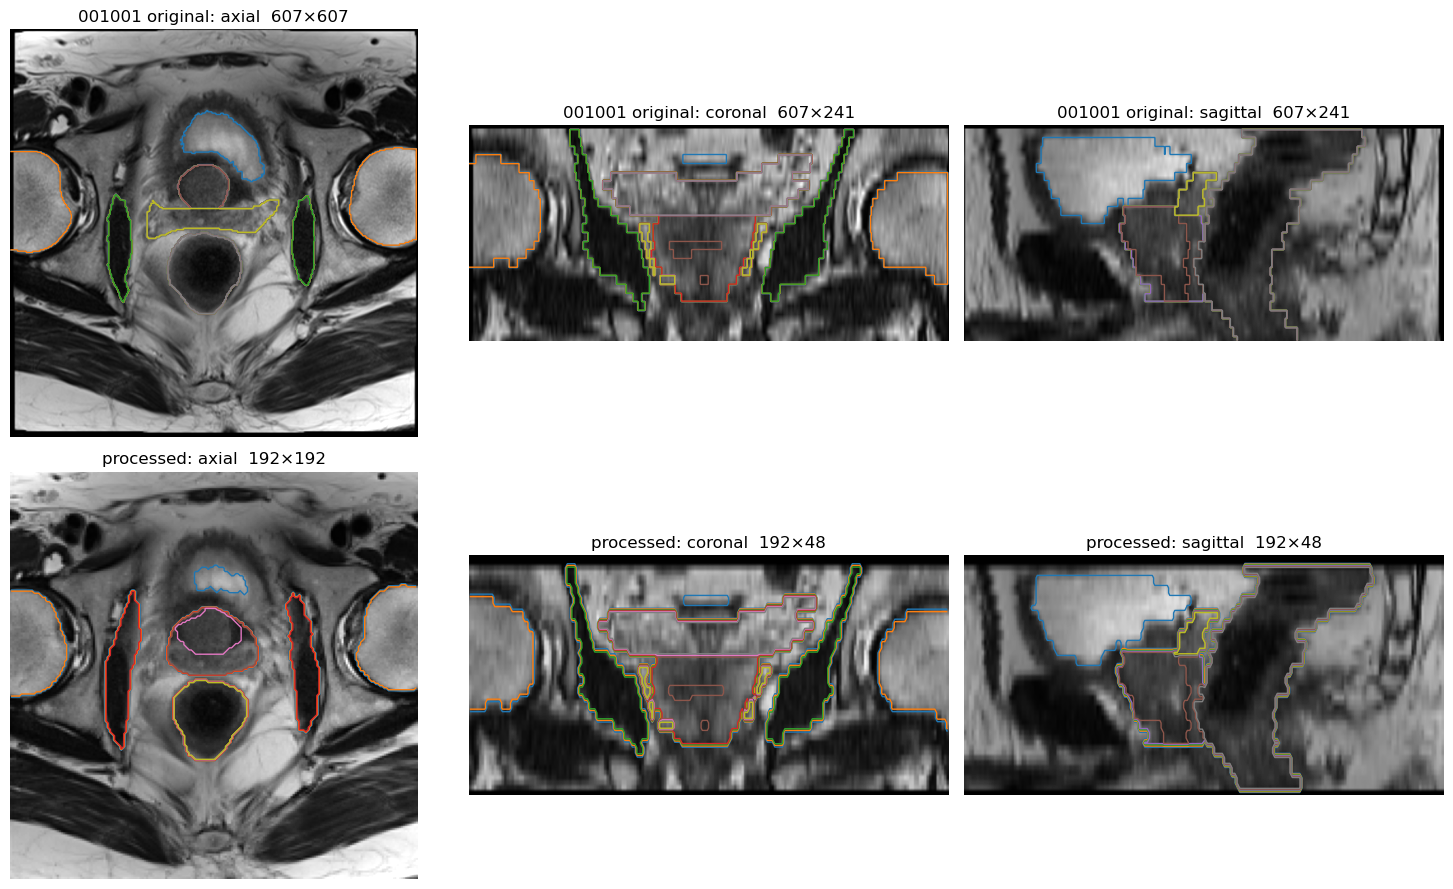

In [ ]:
CASE = 1                          # index into cases (try others)
c = cases[CASE]

def three_views(img, mask, axes, title):
    arr, lab = sitk.GetArrayViewFromImage(img), sitk.GetArrayViewFromImage(mask)   # (z, y, x)
    sx, sy, sz = img.GetSpacing()
    k, j, i = (np.round(np.argwhere(lab > 0).mean(axis=0)).astype(int) if lab.any()
               else np.array(arr.shape) // 2)                  # centre of the organs
    lo, hi = grey_range(arr)
    for ax, (name, im, lb, asp, org) in zip(axes, [
            ("axial", arr[k], lab[k], sy / sx, "upper"),
            ("coronal", arr[:, j], lab[:, j], sz / sx, "lower"),
            ("sagittal", arr[:, :, i], lab[:, :, i], sz / sy, "lower")]):
        ax.imshow(im, cmap="gray", vmin=lo, vmax=hi, aspect=asp, origin=org)
        if lb.any():
            ax.contour(lb, levels=np.arange(0.5, lb.max() + 1), cmap="tab10", linewidths=1)
        ax.set_title(f"{title}: {name}  {im.shape[1]}×{im.shape[0]}")
        ax.axis("off")

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
three_views(c["img"], c["mask"], axes[0], f'{c["case"]} original')
three_views(c["img_out"], c["mask_out"], axes[1], "processed")
plt.tight_layout(); plt.show()

## 7 · Save the processed data

Same file names as the input, in `OrganDataProcessed/`:
* image as **float32**: enough precision for intensities, half the size of float64;
* mask as **uint8**: labels 0–8 are whole numbers, 1 byte per voxel is enough.

`sitk.WriteImage` stores the geometry (spacing, origin, direction) in the header, so the processed files still overlay correctly in ITK-SNAP or 3D Slicer.

In [ ]:
OUT_DIR.mkdir(exist_ok=True)
for (img_path, mask_path), c in zip(pairs, cases):
    sitk.WriteImage(sitk.Cast(c["img_out"], sitk.sitkFloat32), str(OUT_DIR / img_path.name))
    sitk.WriteImage(sitk.Cast(c["mask_out"], sitk.sitkUInt8), str(OUT_DIR / mask_path.name))

# Re-read the headers of what we wrote: this is the "list the data" table of step 2, for the output
saved = []
for img_path, mask_path in find_pairs(OUT_DIR):
    hi, hm = header_info(img_path), header_info(mask_path)
    saved.append({"case": img_path.name.replace(IMG_SUFFIX, "").split(".")[0],
                  "size": hi.GetSize(), "spacing": hi.GetSpacing(),
                  "image dtype": sitk.GetPixelIDValueAsString(hi.GetPixelID()),
                  "mask dtype": sitk.GetPixelIDValueAsString(hm.GetPixelID()),
                  "image MB": round(img_path.stat().st_size / 1e6, 1),
                  "mask MB": round(mask_path.stat().st_size / 1e6, 1)})
saved = pd.DataFrame(saved)
total_in = sum(i.stat().st_size + m.stat().st_size for i, m in pairs) / 1e6
total_out = (saved["image MB"].sum() + saved["mask MB"].sum())
print(f"saved {len(saved)} cases to {OUT_DIR.resolve()}")
print(f"total size: {total_in:.0f} MB before  ->  {total_out:.0f} MB after")
saved

saved 17 cases to <teaching-data>/OrganDataProcessed
total size: 1013 MB before  ->  151 MB after


,case,size,spacing,image dtype,mask dtype,image MB,mask MB
0,001000,"(192, 192, 48)","(1.0, 1.0, 2.0)",32-bit float,8-bit unsigned integer,7.1,1.8
1,001001,"(192, 192, 48)","(1.0, 1.0, 2.0)",32-bit float,8-bit unsigned integer,7.1,1.8
2,001002,"(192, 192, 48)","(1.0, 1.0, 2.0)",32-bit float,8-bit unsigned integer,7.1,1.8
3,001003,"(192, 192, 48)","(1.0, 1.0, 2.0)",32-bit float,8-bit unsigned integer,7.1,1.8
4,001004,"(192, 192, 48)","(1.0, 1.0, 2.0)",32-bit float,8-bit unsigned integer,7.1,1.8
5,001005,"(192, 192, 48)","(1.0, 1.0, 2.0)",32-bit float,8-bit unsigned integer,7.1,1.8
6,001006,"(192, 192, 48)","(1.0, 1.0, 2.0)",32-bit float,8-bit unsigned integer,7.1,1.8
7,002000,"(192, 192, 48)","(1.0, 1.0, 2.0)",32-bit float,8-bit unsigned integer,7.1,1.8
8,002002,"(192, 192, 48)","(1.0, 1.0, 2.0)",32-bit float,8-bit unsigned integer,7.1,1.8
9,002003,"(192, 192, 48)","(1.0, 1.0, 2.0)",32-bit float,8-bit unsigned integer,7.1,1.8


## Summary and exercises

| step | what | why |
|---|---|---|
| list header | size, spacing, extent, dtype | know your data before changing it |
| check | mask geometry = image geometry, LPS | catch silent mismatches |
| resample | to 1 × 1 × 2 mm (image linear, mask nearest) | same physical size per voxel |
| crop / pad | to 192 × 192 × 48 | same array size for batching |
| save | image float32, mask uint8 | correct types, smaller files |

To train on the result, set `DATA_DIR = "../../OrganDataProcessed"` and `LBL_SUFFIX = "_mask"` in `unet_mini_example.ipynb`.

**Exercises**
1. Resample the **mask with linear** interpolation instead of nearest. Which label values appear? Why is that wrong?
2. Change `TARGET_SPACING` to `(2, 2, 4)` and `(0.5, 0.5, 1)`. How do the sizes, file sizes and the small organs change?
3. Set `TARGET_SIZE = (208, 208, 64)` and then `(160, 160, 40)`. Which cases lose organ voxels now?
4. Instead of the image centre, centre the crop on the **mask bounding box**. Why can you not do this for new test scans that have no mask?
5. Run step 2 on `OrganDataBeforeLarge`. Which dtypes do you see, and how much space do they waste?